In [5]:
# 作业1：Global methane levels from 2002

# 数据处理准备：读取数据，换算为ppb
# 题目要求用ppb作图，但文件中xch4的单位属性是1，经差表示无量纲摩尔分数：文件中的0.0000018对应1800ppb
# 还要先处理文件用来表示缺测的1e20，否则它会把平均值拉得极大
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

# 只读取这次作业需要的xch4变量和时间范围
# load()把数据读入内存，退出with后仍然可以使用
ds = xr.open_dataset("200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc")
raw = ds["xch4"].sel(time=slice("2003-01", "2020-06")).load()
ds.close()
    
# 用where来筛选不为缺测的值
raw = raw.where(raw != np.float32(1e20))

# 将摩尔分数换算为ppb。
ch4 = raw.astype("float64") * 1e9
ch4.attrs["units"] = "ppb"

print(ch4.dims)
print(ch4.shape)

('time', 'lat', 'lon')
(210, 36, 72)


('month', 'lat', 'lon')
(12, 36, 72)


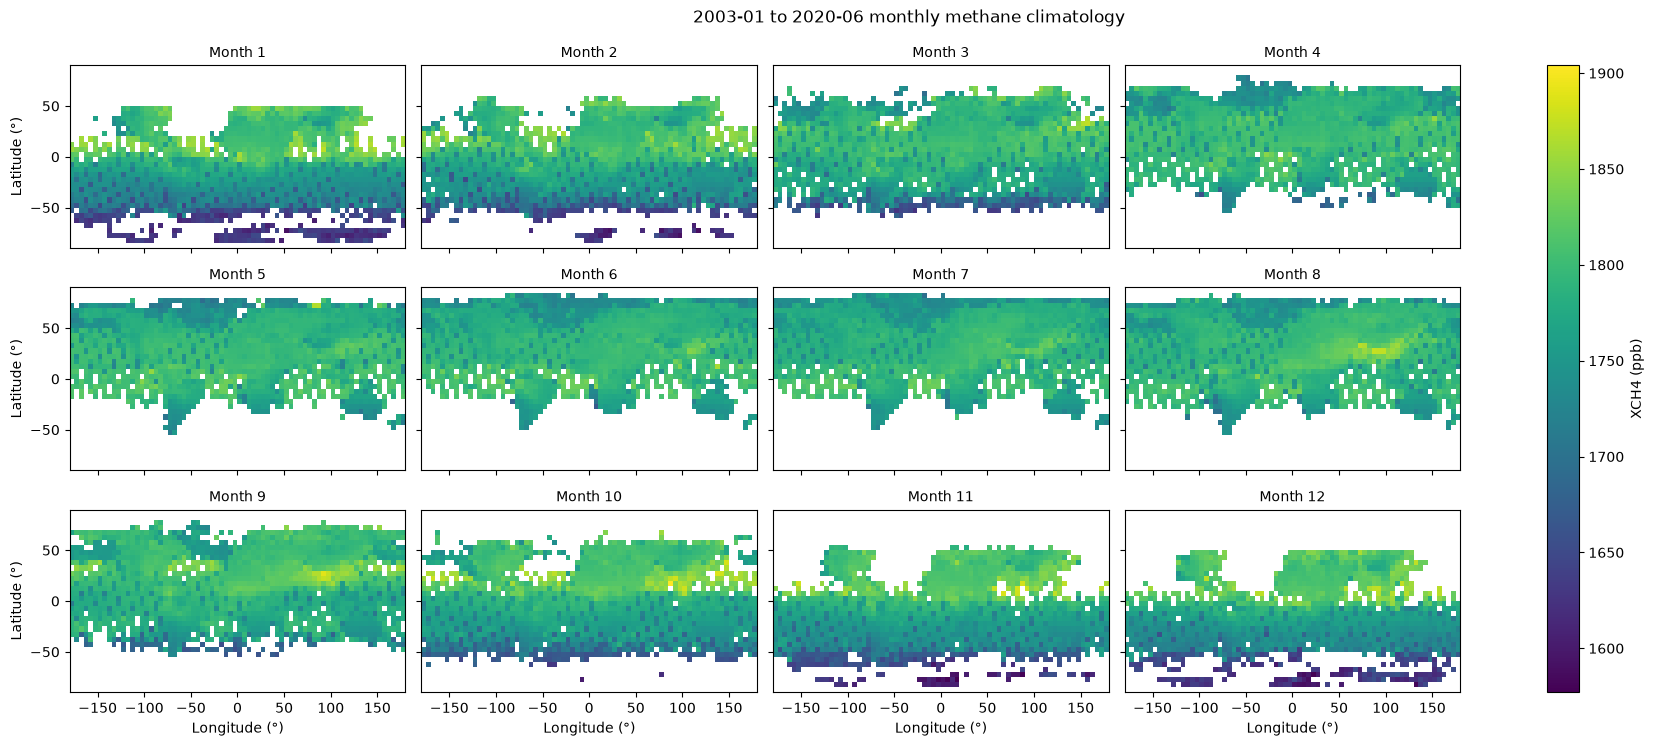

In [4]:
# 题目1.1：计算甲烷每个月的全球平均值，并将结果绘制为12张子图

# 使用skipna=True来跳过缺测值
# 使用groupby把所有年份的对应月放在一起，然后用mean只沿时间维度求平均，保留每个格点的位置
clim = ch4.groupby("time.month").mean(dim="time", skipna=True)

print(clim.dims)
print(clim.shape)

# x和y指定地图横纵轴，col="month"每个月画一幅，col_wrap=4每行放4幅（这样自动排成3行）
panels = clim.plot.pcolormesh(
    x="lon", y="lat",
    col="month", col_wrap=4,
    cmap="viridis", size=2.4, aspect=1.8,
    cbar_kwargs={"label": "XCH4 (ppb)"}
)

#设置子图的名字、坐标轴的标签以及整个大图的名字
panels.set_titles("Month {value}")
panels.set_axis_labels("Longitude (°)", "Latitude (°)")
panels.fig.suptitle("2003-01 to 2020-06 monthly methane climatology", y=1.03)
plt.show()

2003-01 全球均值：1713.49 ppb
2020-06 全球均值：1850.67 ppb
全球有效月数： 209


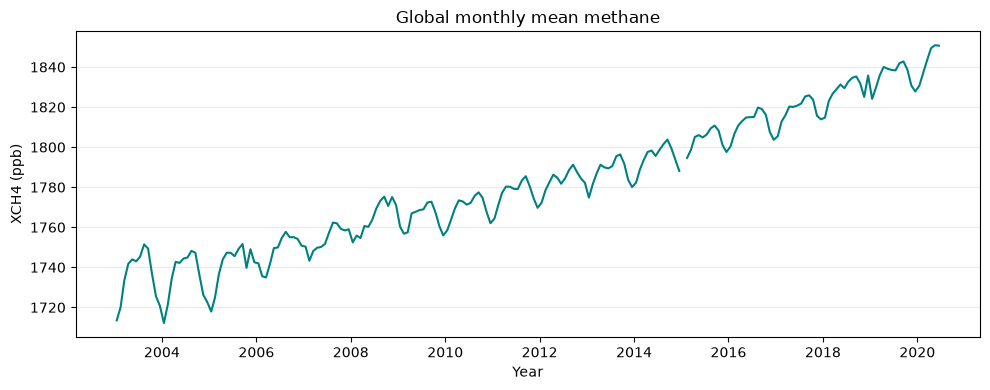

In [4]:
# 题目1.2：绘制全球平均甲烷浓度时间序列图

# 这里对每个月有观测的格点做面积加权平均。虽然格点都是5°×5°，但高纬度格点的实际面积比赤道附近小，对这种规则经纬度网格，可以用纬度的余弦作为面积权重。
# 该思路根据官方xarray文档面积加权平均示例：https://docs.xarray.dev/en/stable/examples/area_weighted_tempery

# np.cos 使用弧度，因此先把纬度从角度转换为弧度
weights = np.cos(np.deg2rad(ch4.lat))
# 同时对lat和lon求加权平均，保留time维度
global_mean = ch4.weighted(weights).mean(dim=("lat", "lon"), skipna=True)

# isel 按位置取值：0 是第一个月，-1 是最后一个月。
print(f"2003-01 全球均值：{global_mean.isel(time=0).item():.2f} ppb")
print(f"2020-06 全球均值：{global_mean.isel(time=-1).item():.2f} ppb")
print("全球有效月数：", global_mean.count().item())

# 绘制甲烷的全球平均时间序列图
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(global_mean.time, global_mean, color="teal", linewidth=1.5)
ax.set(title="Global monthly mean methane", xlabel="Year", ylabel="XCH4 (ppb)")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

实际格点（纬度，经度）： -12.5 -147.5
该格点有效月数： 77
距平范围：-82.04 至 61.00 ppb


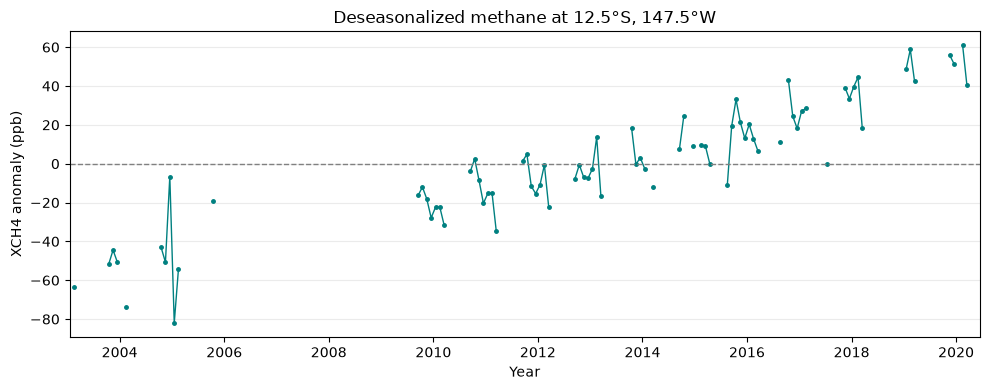

In [5]:
# 题目1.3：绘制 15°S、150°W 附近的去季节化的甲烷浓度时间序列图

# 南纬、西经均用负数表示
point = ch4.sel(lat=-15, lon=-150, method="nearest")
print("实际格点（纬度，经度）：", point.lat.item(), point.lon.item())
# 从1.1的气候态中取出同一个格点，得到该点的12个逐月平均值
point_clim = clim.sel(lat=point.lat, lon=point.lon)

# xarray按月份匹配：每个一月减去一月平均，每个二月减去二月平均......以此类推
anomaly = point.groupby("time.month") - point_clim
# 输出有效月数和格点距平范围
print("该格点有效月数：", anomaly.count().item())
print(f"距平范围：{anomaly.min().item():.2f} 至 {anomaly.max().item():.2f} ppb")

# 绘制时间序列图图
fig, ax = plt.subplots(figsize=(10, 4))
# ".-"同时画点和线。即使前后两个月都缺测，单个有效观测也能显示
# 保留 NaN，让缺测时段自然断开
ax.plot(anomaly.time, anomaly, ".-", color="teal", linewidth=1, markersize=5)
ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.set_xlim(ch4.time.values[0], ch4.time.values[-1])
ax.set(title="Deseasonalized methane at 12.5°S, 147.5°W",
       xlabel="Year", ylabel="XCH4 anomaly (ppb)")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()